In [129]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [130]:
# 1. Campioni e relative concentrazioni dichiarate
target_samples = ["Sample 1", "Sample 2", "Sample 3", "Sample 4", "Sample 5"]
concs = np.array([1, 2, 3, 4, 5])/ 4  # [ATP] in mM

In [131]:
# Cartella di output per il salvataggio dei risultati grafici
OUTPUT_DIR = Path(fr"C:/Users/lucaasinari/Desktop/Tesi ESPCI/script_rheoflu/results/phase_diagram/nanodrop_calibration")
if not OUTPUT_DIR.is_absolute() or not OUTPUT_DIR.drive or not Path(OUTPUT_DIR.drive + "/").exists():
    OUTPUT_DIR = Path(str(OUTPUT_DIR).replace("C:", "").replace("c:", ""))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"I grafici verranno salvati in: {OUTPUT_DIR}")

folder_path = Path("/Users/lucaasinari/Desktop/Tesi ESPCI/esperimenti/data/nanodrop/NanodropOne_AZY2123940")
filenames = [
    "UV-Vis 10_19_2026 2_55_02 PM.csv",
]
pixel_size_um = 62/280

# Funzione di lettura flessibile (gestisce sia file salvati da Excel sia file grezzi NanoDrop)
def load_nanodrop(path):
    try:
        df = pd.read_csv(path, sep=None, engine="python").dropna(how="all", axis=1)
        if df.shape[1] > 1:
            return df
    except Exception:
        pass
    return pd.read_csv(path, sep="\t", encoding="utf-16").dropna(how="all", axis=1)

dfs = []
for fname in filenames:
    file_csv = folder_path / fname
    print(f"Caricamento file: {file_csv.name}")
    dfs.append(load_nanodrop(file_csv))


df = pd.concat(dfs, ignore_index=True)
print(f"\nTotale campioni caricati: {len(df)}\n")

# Mostra la tabella a video
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
print(df.to_string(index=False))

I grafici verranno salvati in: /Users/lucaasinari/Desktop/Tesi ESPCI/script_rheoflu/results/phase_diagram/nanodrop_calibration
Caricamento file: UV-Vis 10_19_2026 2_55_02 PM.csv

Totale campioni caricati: 28

                 Date    Sample Name Automated Pathlength Analytical Wavelength  245 nm  250 nm  255 nm  260 nm  265 nm  270 nm  275 nm  244 nm  246 nm  251 nm  256 nm  261 nm  266 nm  271 nm  276 nm  243 nm  247 nm  252 nm  257 nm  262 nm  267 nm  272 nm  277 nm  242 nm  248 nm  253 nm  258 nm  263 nm  268 nm  273 nm  278 nm  241 nm  249 nm  254 nm  259 nm  264 nm  269 nm  274 nm  279 nm  240 nm
10/19/2026 2:54:58 PM       Sample 1                  OFF                   OFF    1.82    2.45    2.98    3.16    2.91    2.14    1.23    1.70    1.97    2.58    3.05    3.13    2.79    1.94    1.09    1.60    2.10    2.71    3.11    3.10    2.66    1.76    0.94    1.49    2.21    2.82    3.14    3.05    2.50    1.58    0.80    1.39    2.32    2.91    3.16    2.99    2.33    1.40    0.66

Grafico salvato in: /Users/lucaasinari/Desktop/Tesi ESPCI/script_rheoflu/results/phase_diagram/nanodrop_calibration/Atp_linear_intensity.png


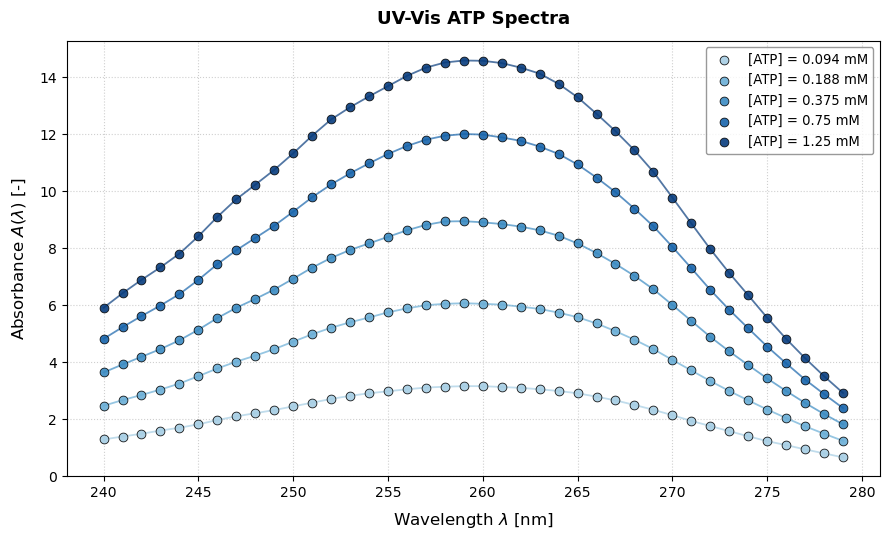

In [132]:
# =============================================================================
# SPETTRO UV-VIS: ASSORBANZA (SCALA LINEARE) VS LUNGHEZZA D'ONDA (SAMPLE 1 - SAMPLE 5)
# =============================================================================

# 1. Identificazione e ordinamento numerico delle lunghezze d'onda
wl_cols = [c for c in df.columns if "nm" in str(c).lower()]

def parse_wl(col):
    try:
        return float(col.lower().replace("nm", "").strip())
    except ValueError:
        return None

wl_dict = {c: parse_wl(c) for c in wl_cols if parse_wl(c) is not None}
sorted_cols = sorted(wl_dict.keys(), key=lambda c: wl_dict[c])
wavelengths = np.array([wl_dict[c] for c in sorted_cols])

# 2. Campioni da estrarre e rispettive etichette [ATP] per la legenda
target_samples = ["Sample 1", "Sample 2", "Sample 3", "Sample 4", "Sample 5"]

raw_labels = ["[ATP]=0.094mM", "[ATP]= 0.188 mM", "[ATP]= 0.375 mM", "[ATP]= 0.75 mM", "[ATP]= 1.25 mM"]
labels = [l.replace("[ATP]=", "[ATP] = ").replace("mM", " mM").replace("  ", " ") for l in raw_labels]

blues = plt.cm.Blues(np.linspace(0.35, 0.95, len(target_samples)))

plt.figure(figsize=(9, 5.5), dpi=100)

sample_col_series = df["Sample Name"].astype(str).str.strip().str.lower()
lambda_info = []

for sample_name, label_text, color in zip(target_samples, labels, blues):
    row = df[sample_col_series == sample_name.lower()]
    if row.empty:
        print(f"Attenzione: '{sample_name}' non trovato nel DataFrame.")
        continue
    
    # Valori di assorbanza grezzi in scala lineare
    absorbances = row[sorted_cols].iloc[0].values.astype(float)
    
    # Calcolo della lunghezza d'onda di massima assorbanza
    max_idx = np.argmax(absorbances)
    max_wl = wavelengths[max_idx]
    lambda_info.append(f"{sample_name} ({label_text}): λ_max = {max_wl:.0f} nm")
    
    # Punti del campione dello stesso colore (scala lineare)
    plt.scatter(
        wavelengths, absorbances,
        color=color,
        s=40,
        edgecolors="black",
        linewidth=0.6,
        alpha=0.9,
        label=label_text,
        zorder=3
    )
    # Linea continua dello stesso blu per seguire il profilo dello spettro
    plt.plot(
        wavelengths, absorbances,
        color=color,
        linestyle="-",
        linewidth=1.3,
        alpha=0.7,
        zorder=2
    )

# 3. Formattazione assi ed etichette
plt.xlabel("Wavelength $\lambda$ [nm]", fontsize=12, labelpad=8)
plt.ylabel("Absorbance $A(\lambda)$ [-]", fontsize=12, labelpad=8)
plt.title("UV-Vis ATP Spectra", fontsize=13, fontweight="bold", pad=12)
plt.ylim(bottom=0)  # Minimo a 0, massimo automatico
plt.grid(True, linestyle=":", alpha=0.6, zorder=1)
plt.legend(frameon=True, facecolor="white", edgecolor="gray", fontsize=9.5, loc="upper right")
plt.tight_layout()


# 4. Salvataggio della figura se definita OUTPUT_DIR
if "OUTPUT_DIR" in globals():
    save_path = OUTPUT_DIR / "Atp_linear_intensity.png"
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"Grafico salvato in: {save_path}")

plt.show()

Lunghezze d'onda di massima assorbanza (λ_max):
  • Sample 1 (0.094 mM): λ_max = 259 nm
  • Sample 2 (0.188 mM): λ_max = 259 nm
  • Sample 3 (0.375 mM): λ_max = 259 nm
  • Sample 4 (0.750 mM): λ_max = 259 nm
  • Sample 5 (1.250 mM): λ_max = 259 nm
Grafico salvato in: /Users/lucaasinari/Desktop/Tesi ESPCI/script_rheoflu/results/phase_diagram/nanodrop_calibration/Atp_log_intensity.png


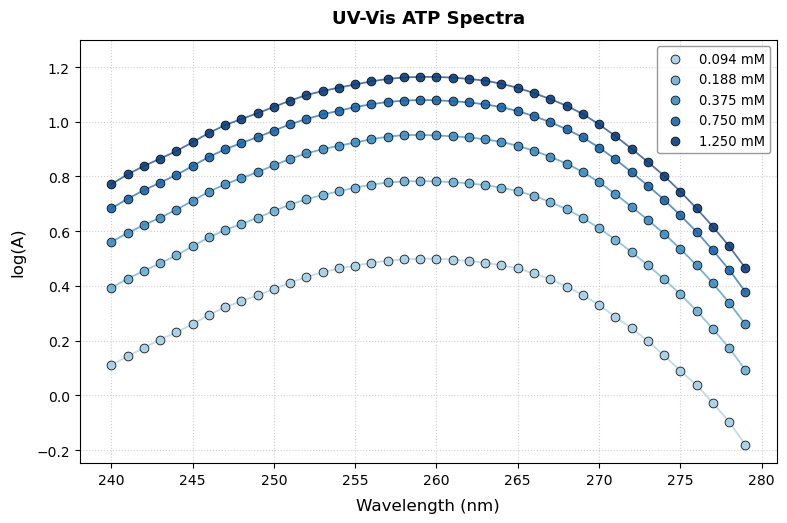

In [133]:
# =============================================================================
# SPETTRO UV-VIS: LOG(INTENSITÀ) VS LUNGHEZZA D'ONDA (SAMPLE 1 - SAMPLE 5)
# =============================================================================

# 1. Identificazione e ordinamento numerico delle lunghezze d'onda (colonne con 'nm')
wl_cols = [c for c in df.columns if "nm" in str(c).lower()]

def parse_wl(col):
    try:
        return float(col.lower().replace("nm", "").strip())
    except ValueError:
        return None

wl_dict = {c: parse_wl(c) for c in wl_cols if parse_wl(c) is not None}
sorted_cols = sorted(wl_dict.keys(), key=lambda c: wl_dict[c])
wavelengths = [wl_dict[c] for c in sorted_cols]

# 2. Campioni da estrarre e rispettive etichette [ATP] per la legenda
target_samples = ["Sample 1", "Sample 2", "Sample 3", "Sample 4", "Sample 5"]

raw_labels = ["0.094mM", "0.188 mM", "0.375 mM", "0.750 mM", "1.250 mM"]
# Uniformazione della formattazione con spazi coerenti: '[ATP] = X.XXX mM'
labels = [l.replace("[ATP]=", "[ATP] = ").replace("mM", " mM").replace("  ", " ") for l in raw_labels]

blues = plt.cm.Blues(np.linspace(0.35, 0.95, len(target_samples)))

plt.figure(figsize=(9, 5.5), dpi=100)

sample_col_series = df["Sample Name"].astype(str).str.strip().str.lower()

lambda_info = []

for sample_name, label_text, color in zip(target_samples, labels, blues):
    row = df[sample_col_series == sample_name.lower()]
    if row.empty:
        print(f"Attenzione: '{sample_name}' non trovato nel DataFrame.")
        continue
    
    # Estrazione valori di intensità ordinati per lunghezza d'onda
    absorbances = row[sorted_cols].iloc[0].values.astype(float)
    
    # Calcolo della lunghezza d'onda di massima assorbanza (lambda max)
    max_idx = np.argmax(absorbances)
    max_wl = wavelengths[max_idx]
    lambda_info.append(f"{sample_name} ({label_text}): $\\lambda_{{\\mathrm{{max}}}} = {max_wl:.0f}$ nm")
    
    # Calcolo del logaritmo (con gestione di valori non positivi)
    with np.errstate(invalid="ignore", divide="ignore"):
        log_absorbance = np.where(absorbances > 0, np.log10(absorbances), np.nan) #np.log10 
    
    # Punti del campione dello stesso colore
    plt.scatter(
        wavelengths, log_absorbance,
        color=color,
        s=40,
        edgecolors="black",
        linewidth=0.6,
        alpha=0.9,
        label=label_text,
        zorder=3
    )
    # Linea continua dello stesso blu per seguire il profilo dello spettro
    plt.plot(
        wavelengths, log_absorbance,
        color=color,
        linestyle="-",
        linewidth=1.3,
        alpha=0.7,
        zorder=2
    )

# 3. Formattazione assi ed etichette
plt.xlabel("Wavelength (nm)", fontsize=12, labelpad=8)
plt.ylabel("log(A)", fontsize=12, labelpad=8)
plt.title("UV-Vis ATP Spectra", fontsize=13, fontweight="bold", pad=12)
plt.ylim(None,1.3)
plt.grid(True, linestyle=":", alpha=0.6, zorder=1)
plt.legend(frameon=True, facecolor="white", edgecolor="gray", fontsize=9.5, loc="upper right")


# Stampa a video dei valori
print("Lunghezze d'onda di massima assorbanza (λ_max):")
for s in lambda_info:
    clean_s = s.replace("$\\lambda_{\\mathrm{max}} = ", "λ_max = ").replace("$", "")
    print(f"  • {clean_s}")

# 4. Salvataggio della figura se definita OUTPUT_DIR
if "OUTPUT_DIR" in globals():
    save_path = OUTPUT_DIR / "Atp_log_intensity.png"
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"Grafico salvato in: {save_path}")

plt.show()

In [134]:
# =============================================================================
# DETERMINAZIONE DELLA LUNGHEZZA D'ONDA DI MASSIMA ASSORBANZA (LAMBDA MAX)
# =============================================================================

# 1. Identificazione e ordinamento numerico delle lunghezze d'onda
wl_cols = [c for c in df.columns if "nm" in str(c).lower()]

def parse_wl(col):
    try:
        return float(col.lower().replace("nm", "").strip())
    except ValueError:
        return None

wl_dict = {c: parse_wl(c) for c in wl_cols if parse_wl(c) is not None}
sorted_cols = sorted(wl_dict.keys(), key=lambda c: wl_dict[c])
wavelengths = np.array([wl_dict[c] for c in sorted_cols])

# 2. Calcolo e stampa per i campioni di calibrazione ATP (Sample 1 - Sample 5)
target_samples = ["Sample 1", "Sample 2", "Sample 3", "Sample 4", "Sample 5"]
labels = ["[ATP] = 0.094 mM", "[ATP] = 0.188 mM", "[ATP] = 0.375 mM", "[ATP] = 0.75 mM", "[ATP] = 1.25 mM"]

sample_col_series = df["Sample Name"].astype(str).str.strip().str.lower()

table_lines = [
    f"{'Campione':<12} | {'Concentrazione':<18} | {'λ max (nm)':<12} | {'Assorbanza Max':<15}",
    "-" * 65
]

for sample_name, label_text in zip(target_samples, labels):
    row = df[sample_col_series == sample_name.lower()]
    if row.empty:
        continue
    
    absorbances = row[sorted_cols].iloc[0].values.astype(float)
    max_idx = np.argmax(absorbances)
    max_wl = wavelengths[max_idx]
    max_abs = absorbances[max_idx]
    
    table_lines.append(f"{sample_name:<12} | {label_text:<18} | {max_wl:>8.0f} nm | {max_abs:>12.2f}")

for line in table_lines:
    print(line)

# Salvataggio della tabella in un file di testo
if "OUTPUT_DIR" in globals():
    table_file = OUTPUT_DIR / "max_absorbance_peaks.txt"
    with open(table_file, "w", encoding="utf-8") as f:
        f.write("\n".join(table_lines) + "\n")
    print(f"\nTabella salvata in: {table_file}")


Campione     | Concentrazione     | λ max (nm)   | Assorbanza Max 
-----------------------------------------------------------------
Sample 1     | [ATP] = 0.094 mM   |      259 nm |         3.16
Sample 2     | [ATP] = 0.188 mM   |      259 nm |         6.07
Sample 3     | [ATP] = 0.375 mM   |      259 nm |         8.95
Sample 4     | [ATP] = 0.75 mM    |      259 nm |        12.01
Sample 5     | [ATP] = 1.25 mM    |      259 nm |        14.59

Tabella salvata in: /Users/lucaasinari/Desktop/Tesi ESPCI/script_rheoflu/results/phase_diagram/nanodrop_calibration/max_absorbance_peaks.txt


=== REGRESSIONE LINEARE VINCOLATA (A = m * c) - PRIMI 5 PUNTI ===
Lunghezza d'onda:     259 nm
Equazione retta:      A = 11.865 * c
Extinction factor:         11.865 mM^-1 cm^-1
Extinction factor nominale: 15.4
Intercetta (q):       0.000 (vincolata)
R^2 (pt fittati):     0.9983

Grafico salvato in: /Users/lucaasinari/Desktop/Tesi ESPCI/script_rheoflu/results/phase_diagram/nanodrop_calibration/Atp_calibration_linear_A_vs_c.png
Parametri del fit salvati in: /Users/lucaasinari/Desktop/Tesi ESPCI/script_rheoflu/results/phase_diagram/nanodrop_calibration/fit_params_linear_A_vs_c.txt


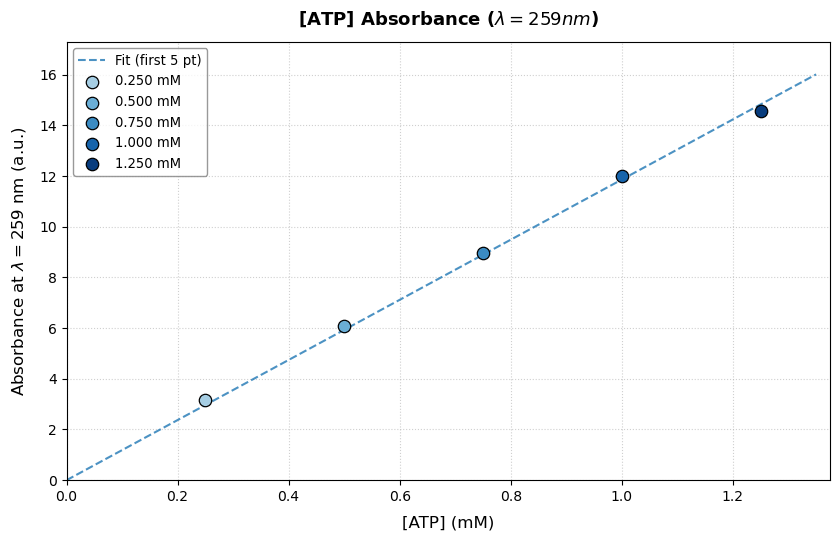

In [135]:
# =============================================================================
# CURVA DI CALIBRAZIONE LINEARE: ASSORBANZA VS CONCENTRAZIONE (SAMPLE 1 - SAMPLE 5)
# =============================================================================

# 2. Identificazione e ordinamento numerico delle lunghezze d'onda
wl_cols = [c for c in df.columns if "nm" in str(c).lower()]

def parse_wl(col):
    try:
        return float(col.lower().replace("nm", "").strip())
    except ValueError:
        return None

wl_dict = {c: parse_wl(c) for c in wl_cols if parse_wl(c) is not None}
sorted_cols = sorted(wl_dict.keys(), key=lambda c: wl_dict[c])
wavelengths = np.array([wl_dict[c] for c in sorted_cols])

# 3. Estrazione dell'assorbanza al picco di massima assorbanza (lambda = 259 nm)
idx_peak = np.where(wavelengths == 259)[0]
idx_peak = idx_peak[0] if len(idx_peak) > 0 else 0
peak_wl = wavelengths[idx_peak]

sample_col_series = df["Sample Name"].astype(str).str.strip().str.lower()
absorbances = []

for s_name in target_samples:
    row = df[sample_col_series == s_name.lower()]
    if not row.empty:
        absorbances.append(row[sorted_cols[idx_peak]].iloc[0])
    else:
        print(f"Attenzione: '{s_name}' non trovato!")

absorbances = np.array(absorbances, dtype=float)

# 4. Selezione dei punti (Opzione A - slicing) e Regressione vincolata a 0: A = m * c
# Modifica n_fit per selezionare quanti punti iniziali includere nel fit (es. 3 o 4)
n_fit = 5
concs_fit = concs[:n_fit]
abs_fit = absorbances[:n_fit]

# Minimi quadrati con intercetta vincolata a 0 sui soli punti selezionati: m = sum(x*y) / sum(x^2)
slope = np.sum(concs_fit * abs_fit) / np.sum(concs_fit**2)
intercept = 0.0

# Calcolo corretto di R^2 per il modello vincolato sui punti fittati
ss_res = np.sum((abs_fit - slope * concs_fit)**2)
ss_tot = np.sum((abs_fit - np.mean(abs_fit))**2)
r_squared = 1 - (ss_res / ss_tot)

# 5. Plotting
plt.figure(figsize=(8.5, 5.5), dpi=100)

# Retta di regressione lineare vincolata estesa su tutto l'intervallo
fit_x = np.linspace(0, concs.max() * 1.08, 100)
fit_y = slope * fit_x
plt.plot(
    fit_x, fit_y, linestyle="--", color="#1f77b4", linewidth=1.5, alpha=0.8, zorder=2,
    label=f"Fit (first {n_fit} pt)"
)

# Punti sperimentali: pieni per quelli fittati, vuoti con bordo tratteggiato per quelli esclusi
blues = plt.cm.Blues(np.linspace(0.35, 0.95, len(target_samples)))
for i, (s_name, c_val, a_val, col) in enumerate(zip(target_samples, concs, absorbances, blues)):
    plt.scatter(
        c_val, a_val, color=col, s=80, edgecolors="black", linewidth=0.9, zorder=4,
        label=f"{c_val:.3f} mM"
    )

# Formattazione assi e limiti
plt.xlabel("[ATP] (mM)", fontsize=12, labelpad=8)
plt.ylabel(f"Absorbance at $\\lambda = {peak_wl:.0f}$ nm (a.u.)", fontsize=12, labelpad=8)
plt.title(f"[ATP] Absorbance ($\\lambda = {peak_wl:.0f} nm$)", fontsize=13, fontweight="bold", pad=12)
plt.xlim(left=0, right=concs.max() * 1.1)
plt.ylim(bottom=0, top=max(absorbances.max(), fit_y.max()) * 1.08)
plt.grid(True, linestyle=":", alpha=0.6, zorder=1)
plt.legend(frameon=True, facecolor="white", edgecolor="gray", fontsize=9.5, loc="upper left")
plt.tight_layout()

# Stampa a video dei parametri del fit
fit_lines = [
    f"=== REGRESSIONE LINEARE VINCOLATA (A = m * c) - PRIMI {n_fit} PUNTI ===",
    f"Lunghezza d'onda:     {peak_wl:.0f} nm",
    f"Equazione retta:      A = {slope:.3f} * c",
    f"Extinction factor:         {slope:.3f} mM^-1 cm^-1",
    f"Extinction factor nominale: 15.4",
    f"Intercetta (q):       0.000 (vincolata)",
    f"R^2 (pt fittati):     {r_squared:.4f}"
]

for line in fit_lines:
    print(line)

# 6. Salvataggio della figura e dei parametri se definita OUTPUT_DIR
if "OUTPUT_DIR" in globals():
    save_path = OUTPUT_DIR / "Atp_calibration_linear_A_vs_c.png"
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"\nGrafico salvato in: {save_path}")
    
    fit_params_file = OUTPUT_DIR / "fit_params_linear_A_vs_c.txt"
    with open(fit_params_file, "w", encoding="utf-8") as f:
        f.write("\n".join(fit_lines) + "\n")
    print(f"Parametri del fit salvati in: {fit_params_file}")

plt.show()


Lunghezza d'onda:     259 nm
Pendenza (fissata): 1.0
Intercetta:        1.0819
R^2:               0.9977
Extinction factor: 12.074889462835287
Extinction factor nominale: 15.4


Grafico salvato in: /Users/lucaasinari/Desktop/Tesi ESPCI/script_rheoflu/results/phase_diagram/nanodrop_calibration/Atp_logA_vs_logC.png
Parametri del fit salvati in: /Users/lucaasinari/Desktop/Tesi ESPCI/script_rheoflu/results/phase_diagram/nanodrop_calibration/fit_params_logA_vs_logC.txt


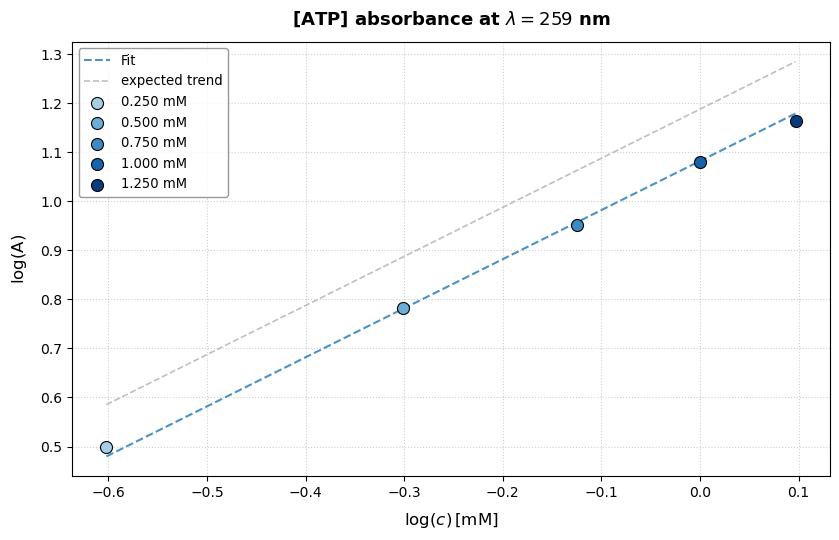

In [136]:
# =============================================================================
# CURVA DI CALIBRAZIONE: LOG(I) VS LOG(c) (SAMPLE 1 - SAMPLE 5)
# =============================================================================

# 2. Identificazione e ordinamento delle lunghezze d'onda
wl_cols = [c for c in df.columns if "nm" in str(c).lower()]

def parse_wl(col):
    try:
        return float(col.lower().replace("nm", "").strip())
    except ValueError:
        return None

wl_dict = {c: parse_wl(c) for c in wl_cols if parse_wl(c) is not None}
sorted_cols = sorted(wl_dict.keys(), key=lambda c: wl_dict[c])
wavelengths = np.array([wl_dict[c] for c in sorted_cols])

# 3. Estrazione delle intensità per ciascun campione
sample_col_series = df["Sample Name"].astype(str).str.strip().str.lower()
absorbances_matrix = []
for s_name in target_samples:
    row = df[sample_col_series == s_name.lower()]
    if not row.empty:
        absorbances_matrix.append(row[sorted_cols].iloc[0].values.astype(float))
    else:
        print(f"Attenzione: '{s_name}' non trovato!")
absorbances_matrix = np.array(absorbances_matrix)  # matrice (5 campioni, n_wavelengths)

# Scelta del tipo di logaritmo (np.log10 o np.log)
log_fn = np.log10  # cambia con np.log se desideri il logaritmo naturale
log_label_x = r"$\log(c)\,\mathrm{[mM]}$" if log_fn == np.log10 else r"$\ln(c)\,\mathrm{[mM]}$"
log_label_y = r"$\log(\mathrm{A})$" if log_fn == np.log10 else r"$\ln(\mathrm{A})$"

log_c = log_fn(concs)

# Selezioniamo la lunghezza d'onda di picco dell'ATP (259 nm)
idx_peak = np.where(wavelengths == 259)[0]
idx_peak = idx_peak[0] if len(idx_peak) > 0 else np.argmax(absorbances_matrix.mean(axis=0))
peak_wl = wavelengths[idx_peak]
peak_absorbances = absorbances_matrix[:, idx_peak]
log_peak_absorbances = log_fn(peak_absorbances)

# Regressione lineare log(A) vs log(c) a lambda_max con pendenza fissata a 1
# Modello: y = 1 * x + q  =>  q = mean(y - x)
slope = 1.0
intercept = np.mean(log_peak_absorbances - log_c)

# Calcolo corretto di R^2 per il modello a pendenza fissa
ss_res = np.sum((log_peak_absorbances - (slope * log_c + intercept))**2)
ss_tot = np.sum((log_peak_absorbances - np.mean(log_peak_absorbances))**2)
r_squared = 1 - (ss_res / ss_tot)

# Stampa a video dei parametri e dell'extinction factor (10^intercept)
extinction_factor = 10**intercept
log_fit_lines = [
    f"Lunghezza d'onda:     {peak_wl:.0f} nm",
    f"Pendenza (fissata): {slope:.1f}",
    f"Intercetta:        {intercept:.4f}",
    f"R^2:               {r_squared:.4f}",
    f"Extinction factor: {extinction_factor}",
    f"Extinction factor nominale: 15.4"
]

for line in log_fit_lines:
    print(line)

# 4. Plotting
plt.figure(figsize=(8.5, 5.5), dpi=100)

# Retta di fit lineare per lambda_max
fit_x = np.linspace(log_c.min(), log_c.max(), 100)
fit_y = slope * fit_x + intercept
plt.plot(
    fit_x, fit_y, linestyle="--", color="#1f77b4", linewidth=1.5, alpha=0.8, zorder=2,
    label=f"Fit"
)

# Linea di riferimento tratteggiata in grigio con pendenza 1 e intercetta = log(15.4)
ref_intercept = log_fn(15.4)
ref_y = 1.0 * fit_x + ref_intercept
plt.plot(
    fit_x, ref_y, linestyle="--", color="gray", linewidth=1.2, alpha=0.5, zorder=1,
    label="expected trend"
)

# Punti dei 5 campioni colorati dal blu più chiaro (Sample 1) al più scuro (Sample 5)
blues = plt.cm.Blues(np.linspace(0.35, 0.95, len(target_samples)))
for s_name, c_val, lc, li, col in zip(target_samples, concs, log_c, log_peak_absorbances, blues):
    plt.scatter(
        lc, li, color=col, s=75, edgecolors="black", linewidth=0.8, zorder=4,
        label=f"{c_val:.3f} mM"
    )

plt.xlabel(log_label_x, fontsize=12, labelpad=8)
plt.ylabel(log_label_y, fontsize=12, labelpad=8)
plt.title(f"[ATP] absorbance at $\\lambda = {peak_wl:.0f}$ nm", fontsize=13, fontweight="bold", pad=12)
plt.grid(True, linestyle=":", alpha=0.6, zorder=1)
plt.legend(frameon=True, facecolor="white", edgecolor="gray", fontsize=9.5, loc="upper left")
plt.tight_layout()

# Salvataggio della figura e dei parametri del fit se definita OUTPUT_DIR
if "OUTPUT_DIR" in globals():
    save_path = OUTPUT_DIR / "Atp_logA_vs_logC.png"
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    print(f"Grafico salvato in: {save_path}")
    
    log_params_file = OUTPUT_DIR / "fit_params_logA_vs_logC.txt"
    with open(log_params_file, "w", encoding="utf-8") as f:
        f.write("\n".join(log_fit_lines) + "\n")
    print(f"Parametri del fit salvati in: {log_params_file}")

plt.show()
